# Fase B – Costruzione delle reti

Primo notebook dell'analisi, secondo il piano operativo (`piano_operativo_fragment_multilayer_aggiornato.docx`).
Parte da `fragment_final.jsonl`, che non viene modificato, e crea le tabelle usate dalle fasi C (intra-layer), D (inter-layer) ed E (comportamento).

**Regole per il grafo** (da `descrizione_colonne_fragment_final.txt`):

| Riga | Grafo | Possesso |
|---|---|---|
| NULL → A | solo il nodo A | inizia il possesso di A |
| A → B | arco A → B | termina il possesso di A, inizia quello di B |
| B → B | nessun arco | il possesso di B continua |
| Ultimo proprietario | nodo | possesso aperto (`OPEN`) |

**Due versioni della rete.** Alcuni indirizzi sono contratti (marketplace, vault dei prestiti), non attori. Il piano chiede di controllare questi artefatti e la stabilità dei risultati:
* `completa`: le regole applicate alle righe così come sono;
* `senza_contratti`: si tolgono le righe il cui destinatario è un contratto identificato e si riapplicano le stesse regole, quindi `A → contratto → B` diventa `A → B` e `A → contratto → A` non è un arco. È un'elaborazione solo per il grafo: il dataset resta intatto.

**Output** (in `analisi_output/dati/<versione>/`): `transfer_events.parquet`, `holding_periods.parquet`, `edges_usernames.parquet`, `edges_numbers.parquet`, `wallet_layer.parquet`.

## 0. Dati

In [1]:
import json
import numpy as np
import pandas as pd
import pyarrow as pa, pyarrow.json as pj, pyarrow.parquet as pq
import matplotlib.pyplot as plt
import igraph as ig
from analisi_utils import *

stile()
PARQUET = DATI / 'fragment_final.parquet'
# Indirizzi tra i 100 più attivi che risultano contratti su TonAPI (is_wallet = False, controllo del 2026-11-01)
CONTRATTI_VERIFICATI = ['0:ee007f6b', '0:db3907b9', '0:51821d28']

if not PARQUET.exists():     # il JSONL si legge una volta sola: poi si usa il parquet, molto più veloce
    schema = pa.schema([('layer', pa.string()), ('nft', pa.string()), ('asset_name', pa.string()), ('categories', pa.list_(pa.string())),
                        ('sender', pa.string()), ('recipient', pa.string()), ('timestamp', pa.string()), ('sender_acquired_at', pa.string()),
                        ('sender_released_at', pa.string()), ('recipient_acquired_at', pa.string()), ('holding_days_sender', pa.float64()),
                        ('action_type', pa.string()), ('is_purchase', pa.bool_()), ('price_ton', pa.float64()),
                        ('action_id', pa.string()), ('trace_id', pa.string())])
    pq.write_table(pj.read_json(JSONL, read_options=pj.ReadOptions(block_size=64 * 2**20),
                                parse_options=pj.ParseOptions(explicit_schema=schema)), PARQUET, compression='zstd')

d = pd.read_parquet(PARQUET, columns=['layer', 'nft', 'sender', 'recipient', 'timestamp', 'holding_days_sender',
                                      'action_type', 'is_purchase', 'price_ton', 'action_id', 'trace_id'])
d['ts'] = pd.to_datetime(d.timestamp, utc=True, format='ISO8601').astype('datetime64[s, UTC]')
d['ordine'] = np.arange(len(d))         # l'ordine del file è l'ordine cronologico delle azioni di ogni NFT
d = d.drop(columns='timestamp')
print(f'{len(d):,} azioni | {d.nft.nunique():,} NFT | dal {d.ts.min():%Y-%m-%d} al {d.ts.max():%Y-%m-%d}')
d.groupby('layer').agg(azioni=('nft', 'size'), nft=('nft', 'nunique'), prima=('ts', 'min'), ultima=('ts', 'max'))

3,406,889 azioni | 691,773 NFT | dal 2022-11-02 al 2026-10-22


,azioni,nft,prima,ultima
layer,,,,
phone_numbers,834748,136566,2022-12-06 18:04:12+00:00,2026-10-22 02:14:51+00:00
usernames,2572141,555207,2022-11-02 17:13:50+00:00,2026-10-22 00:08:33+00:00


## 1. I tipi di riga

Prima dell'analisi verifichiamo che le regole si possano ricostruire dalle colonne: `sender` deve essere il `recipient` della riga precedente dello stesso NFT.

In [2]:
d = d.sort_values(['nft', 'ordine'], kind='stable', ignore_index=True)

def tipo_riga(sender, recipient):
    return np.select([sender.isna(), sender == recipient], ['NULL -> A', 'B -> B'], 'A -> B')

d['tipo_riga'] = tipo_riga(d.sender, d.recipient)
precedente = d.groupby('nft', sort=False).recipient.shift(1)
stesso = (d.sender == precedente) | (d.sender.isna() & precedente.isna())
print(f'sender coincide con il destinatario precedente: {stesso.mean():.4%} delle righe ({(~stesso).sum()} eccezioni)')
print('ogni NFT ha un solo evento iniziale:', (d[d.tipo_riga == 'NULL -> A'].groupby('nft').size() == 1).all())
print('righe con destinatario mancante:', d.recipient.isna().sum())

def tipo_evento(action_type, is_purchase):
    # Il prezzo assente non vuol dire regalo: è un trasferimento senza pagamento verificato
    return np.select([action_type == 'nft_purchase', is_purchase], ['acquisto_nft_purchase', 'acquisto_nft_transfer'],
                     'trasferimento_senza_prezzo')

d['event_type'] = tipo_evento(d.action_type, d.is_purchase)
tab = pd.crosstab([d.layer, d.tipo_riga], d.event_type, margins=True, margins_name='totale')
salva_tabella(tab, 'b_tipi_di_riga')
tab

sender coincide con il destinatario precedente: 100.0000% delle righe (0 eccezioni)
ogni NFT ha un solo evento iniziale: True
righe con destinatario mancante: 0


event_type               acquisto_nft_purchase  acquisto_nft_transfer  trasferimento_senza_prezzo   totale
layer         tipo_riga                                                                                   
phone_numbers A -> B                     47296                 168695                      440080   656071
              B -> B                        15                   1981                       40115    42111
              NULL -> A                      0                   5488                      131078   136566
usernames     A -> B                     78371                 207800                     1636949  1923120
              B -> B                         0                   7522                       86292    93814
              NULL -> A                      0                 555207                           0   555207
totale                                  125682                 946693                     2334514  3406889

## 2. Quali indirizzi sono contratti

Il file finale non ha più `is_wallet`. Senza scaricare altri dati, identifichiamo i contratti in tre modi:
1. **Etichette già in locale**: `is_wallet = False` nelle history dei file del campione (`dataset_clean/` e `dataset_orphans/`). Chi risulta wallet lì resta wallet.
2. **Controllo manuale dei 100 indirizzi più attivi**: `CONTRATTI_VERIFICATI`.
3. **Struttura**:
   * i destinatari di una "fabbrica" di contratti (un contratto che manda ogni NFT a un indirizzo sempre diverso) sono contratti di vendita o noleggio;
   * chi riceve un NFT da un contratto e lo rimanda sempre allo stesso contratto è il contratto di un noleggio.

La tabella sotto misura la regola 3 sugli indirizzi di cui conosciamo l'etichetta. L'elenco resta parziale: un contratto mai passato da una fabbrica e fuori dal campione rimane tra i nodi.

In [3]:
def etichette_campione():
    etichette = {}
    for f in ['dataset_clean/fragment_numbers_sample_500_clean.csv', 'dataset_clean/fragment_usernames_sample_500_clean.csv',
              'dataset_orphans/orphan_nfts_history.csv']:
        for storia in pd.read_csv(BASE / f, usecols=['history']).history.dropna():
            for evento in json.loads(storia):
                for azione in evento['actions']:
                    dettagli = azione.get(azione['type']) or {}
                    for parte in (dettagli.get('sender'), dettagli.get('recipient')):
                        if parte:
                            etichette[parte['address']] = parte['is_wallet']
    return pd.Series(etichette, name='is_wallet').rename_axis('wallet')

is_wallet = etichette_campione()
wallet_noti = set(is_wallet[is_wallet].index)
presenti = pd.Index(pd.concat([d.sender, d.recipient]).dropna().unique())

fonte = {a: 'etichetta del campione' for a in is_wallet[~is_wallet].index.intersection(presenti)}
fonte |= {a: 'controllo manuale top 100' for a in presenti[presenti.str[:10].isin(CONTRATTI_VERIFICATI)]}

archi = d[d.tipo_riga == 'A -> B']
def fabbriche(contratti):
    uscite = archi[archi.sender.isin(contratti)].groupby('sender').recipient.agg(['size', 'nunique'])
    return uscite[(uscite['size'] >= 20) & (uscite['nunique'] >= 0.9 * uscite['size'])].index

verifica = []
nuovi = archi.loc[archi.sender.isin(fabbriche(set(fonte))), 'recipient'].drop_duplicates()
verifica.append({'regola': 'destinatario di una fabbrica', 'indirizzi': len(nuovi),
                 'risultano contratti nel campione': (is_wallet.reindex(nuovi) == False).sum(),
                 'risultano wallet nel campione': (is_wallet.reindex(nuovi) == True).sum()})
fonte |= {a: 'destinatario di una fabbrica' for a in nuovi if a not in wallet_noti and a not in fonte}

# noleggi: l'NFT arriva da un contratto e torna sempre allo stesso contratto
contratti = set(fonte)
prossimo = d.groupby('nft', sort=False).recipient.shift(-1)
da_contratto = archi[archi.sender.isin(contratti)].assign(torna=lambda x: prossimo.loc[x.index] == x.sender)
per_indirizzo = da_contratto.groupby('recipient').torna.agg(['size', 'sum'])
per_indirizzo = per_indirizzo[(per_indirizzo['size'] == per_indirizzo['sum'])
                              & (archi.groupby('recipient').size().reindex(per_indirizzo.index) == per_indirizzo['size'])
                              & (archi.groupby('sender').size().reindex(per_indirizzo.index) == per_indirizzo['size'])]
verifica.append({'regola': 'noleggio: torna allo stesso contratto', 'indirizzi': len(per_indirizzo),
                 'risultano contratti nel campione': (is_wallet.reindex(per_indirizzo.index) == False).sum(),
                 'risultano wallet nel campione': (is_wallet.reindex(per_indirizzo.index) == True).sum()})
fonte |= {a: 'noleggio: torna allo stesso contratto' for a in per_indirizzo.index if a not in wallet_noti and a not in fonte}

contratti = pd.Series(fonte, name='fonte').rename_axis('wallet').reset_index()
contratti.to_parquet(DATI / 'contratti_identificati.parquet')
tocca = archi.sender.isin(fonte) | archi.recipient.isin(fonte)
print(f'contratti identificati: {len(contratti):,} su {len(presenti):,} indirizzi | righe A -> B che li coinvolgono: {tocca.sum():,} su {len(archi):,} ({tocca.mean():.1%})')
display(contratti.fonte.value_counts().rename('indirizzi').to_frame())
pd.DataFrame(verifica).set_index('regola')

contratti identificati: 224,429 su 669,615 indirizzi | righe A -> B che li coinvolgono: 513,545 su 2,579,191 (19.9%)


,indirizzi
fonte,
noleggio: torna allo stesso contratto,171245
destinatario di una fabbrica,49439
etichetta del campione,3742
controllo manuale top 100,3


,indirizzi,risultano contratti nel campione,risultano wallet nel campione
regola,,,
destinatario di una fabbrica,51625,2165,21
noleggio: torna allo stesso contratto,176122,935,0


## 3. Eventi, possessi e archi per le due versioni

* `transfer_events`: una riga per ogni evento, con il mittente ricostruito (`src`) e il tipo di riga.
* `holding_periods`: una riga per ogni periodo di possesso wallet–NFT. Stato: `COMPLETE` se è concluso, `INFERRED` se è concluso ma il passaggio è avvenuto attraverso un contratto tolto dal grafo, `OPEN` se è ancora in corso (la sua durata non è osservabile).
* `edges_*`: una riga per coppia sender → recipient, con `n_transfers`, `n_distinct_nfts`, `n_vendite` e prezzi calcolati sulle sole vendite con prezzo.
* `wallet_layer`: una riga per coppia wallet–layer, compresi i wallet senza archi.

In [4]:
categorie = pd.read_parquet(PARQUET, columns=['nft', 'categories']).drop_duplicates('nft').set_index('nft').categories

def ricostruisci(d, togli=None):
    e = d[['layer', 'nft', 'recipient', 'ts', 'event_type', 'is_purchase', 'price_ton', 'action_id', 'trace_id']].copy()
    e['pos'] = e.groupby('nft', sort=False).cumcount()
    if togli is not None:
        e = e[~e.recipient.isin(togli)]
    e['src'] = e.groupby('nft', sort=False).recipient.shift(1)
    e['via_contratto'] = (e.pos - e.groupby('nft', sort=False).pos.shift(1)).gt(1)
    e['tipo_riga'] = tipo_riga(e.src, e.recipient)
    return e.rename(columns={'recipient': 'dst'}).drop(columns='pos')

def possessi(e):
    cambi = e[e.tipo_riga != 'B -> B'][['layer', 'nft', 'dst', 'ts', 'event_type', 'via_contratto']].copy()
    gruppo = cambi.groupby('nft', sort=False)
    cambi['released_at'] = gruppo.ts.shift(-1)
    via = gruppo.via_contratto.shift(-1).astype('boolean')
    cambi['status'] = np.select([cambi.released_at.isna(), via.fillna(False).to_numpy(dtype=bool)], ['OPEN', 'INFERRED'], 'COMPLETE')
    cambi['holding_days'] = (cambi.released_at - cambi.ts).dt.total_seconds() / 86400
    return cambi.rename(columns={'dst': 'wallet', 'ts': 'acquired_at', 'event_type': 'acquisito_con'}).drop(columns='via_contratto')

def archi_aggregati(e, layer):
    p = e[(e.layer == layer) & (e.tipo_riga == 'A -> B')]
    v = p[p.is_purchase & p.price_ton.notna()]
    agg = p.groupby(['src', 'dst']).agg(n_transfers=('nft', 'size'), n_distinct_nfts=('nft', 'nunique'), n_vendite=('is_purchase', 'sum'),
                                        primo=('ts', 'min'), ultimo=('ts', 'max'))
    prezzi = v.groupby(['src', 'dst']).price_ton.agg(total_price_ton='sum', median_price_ton='median')
    return agg.join(prezzi).reset_index().rename(columns={'src': 'sender', 'dst': 'recipient'})

def tabella_wallet(e, h):
    p = e[e.tipo_riga == 'A -> B']
    righe = pd.concat([e[e.tipo_riga != 'B -> B'][['layer', 'dst', 'nft', 'ts', 'src']].set_axis(['layer', 'wallet', 'nft', 'ts', 'controparte'], axis=1),
                       p[['layer', 'src', 'nft', 'ts', 'dst']].set_axis(['layer', 'wallet', 'nft', 'ts', 'controparte'], axis=1)])
    righe['giorno'] = righe.ts.dt.floor('D')
    g = righe.groupby(['wallet', 'layer'])
    t = g.agg(n_eventi=('nft', 'size'), nft_distinti=('nft', 'nunique'), controparti=('controparte', 'nunique'),
              giorni_attivi=('giorno', 'nunique'), primo=('ts', 'min'), ultimo=('ts', 'max'))
    k = ['wallet', 'layer']
    ruolo = lambda df, col, nome: df.groupby([col, 'layer']).size().rename(nome).rename_axis(k)
    vendite = p[p.is_purchase & p.price_ton.notna()]
    acquisti = e[(e.tipo_riga != 'B -> B') & e.is_purchase & e.price_ton.notna()]
    extra = pd.concat([ruolo(p, 'dst', 'n_ricevuti'), ruolo(p, 'src', 'n_ceduti'),
                       ruolo(e[e.tipo_riga == 'NULL -> A'], 'dst', 'n_primo_proprietario'),
                       ruolo(acquisti, 'dst', 'n_acquisti'), ruolo(vendite, 'src', 'n_vendite'),
                       acquisti.groupby(['dst', 'layer']).price_ton.sum().rename('volume_acquisti').rename_axis(k),
                       vendite.groupby(['src', 'layer']).price_ton.sum().rename('volume_vendite').rename_axis(k)], axis=1)
    t = t.join(extra)
    colonne = ['n_ricevuti', 'n_ceduti', 'n_primo_proprietario', 'n_acquisti', 'n_vendite', 'volume_acquisti', 'volume_vendite']
    t[colonne] = t[colonne].fillna(0)
    return t.reset_index()

contratti_set = set(contratti.wallet)
riepilogo = []
for variante, togli in {'completa': None, 'senza_contratti': contratti_set}.items():
    e = ricostruisci(d, togli)
    h = possessi(e)
    cartella = cartella_variante(variante)
    e.to_parquet(cartella / 'transfer_events.parquet')
    h.to_parquet(cartella / 'holding_periods.parquet')
    for layer in LAYERS:
        archi_aggregati(e, layer).to_parquet(cartella / f'edges_{FILE[layer]}.parquet')
    tabella_wallet(e, h).to_parquet(cartella / 'wallet_layer.parquet')
    riepilogo.append(e.groupby(['layer', 'tipo_riga']).size().rename(NOME_VARIANTE[variante]))
    if variante == 'completa':
        # la ricostruzione deve restituire il mittente e la durata del dataset
        print('mittente uguale al dataset:', (e.src.fillna('') == d.sender.fillna('')).mean())
        q = e.tipo_riga == 'A -> B'
        conc = h.dropna(subset='holding_days')
        print('durata media dei possessi conclusi uguale al dataset:', round(conc.holding_days.mean(), 4), round(d.holding_days_sender.mean(), 4))
    print(variante, 'possessi per stato:', h.status.value_counts().to_dict(), '| durate negative:', (h.holding_days < 0).sum())
    del e, h
tab = pd.concat(riepilogo, axis=1)
salva_tabella(tab, 'b_righe_per_versione')
tab

mittente uguale al dataset: 1.0


durata media dei possessi conclusi uguale al dataset: 67.0608 67.0608
completa possessi per stato: {'COMPLETE': 2579191, 'OPEN': 691773} | durate negative: 0


senza_contratti possessi per stato: {'COMPLETE': 2065646, 'OPEN': 691759, 'INFERRED': 15911} | durate negative: 0


completa  senza contratti
layer         tipo_riga                           
phone_numbers A -> B       656071           610955
              B -> B        42111            53143
              NULL -> A    136566           136566
usernames     A -> B      1923120          1470602
              B -> B        93814           120126
              NULL -> A    555207           555193

## 4. Controlli sulle reti

Self-loop, componenti, transazioni ripetute e distribuzione dei pesi. Il peso di un arco è il numero di passaggi tra i due wallet.

versione                          senza contratti            completa         
layer                                    Username   Numeri   Username   Numeri
nodi                                      346.133  133.355    554.965  149.031
nodi isolati                               29.494    8.917     29.460    8.916
archi (coppie)                            740.238  308.246  1.148.787  339.635
passaggi                                1.470.602  610.955  1.923.120  656.071
self-loop                                       0        0          0        0
componenti deboli                          37.851   10.128     37.774   10.116
componente gigante (% nodi)                 0.845     0.91      0.904     0.92
archi con più passaggi (%)                  0.233    0.155      0.152    0.143
peso massimo                               13.910    1.299     13.910    1.299
passaggi sugli archi ripetuti (%)           0.614    0.574      0.493    0.556

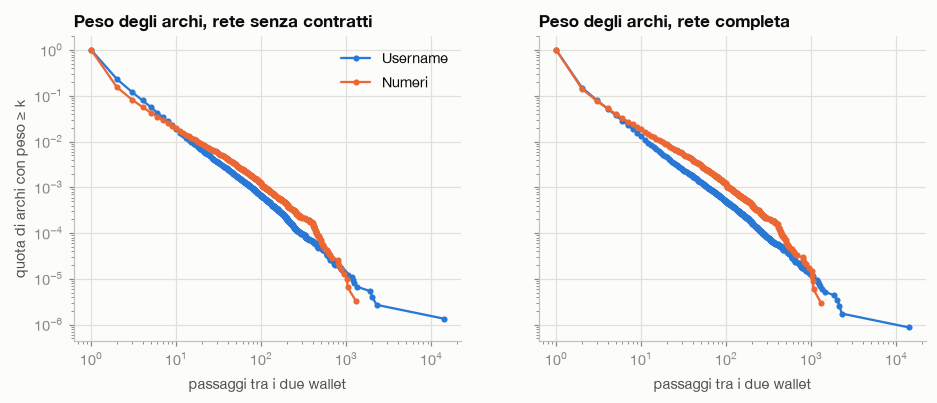

In [5]:
righe = []
pesi = {}
for variante in VARIANTI:
    G = carica_grafi(variante)
    for layer, g in G.items():
        w = np.array(g.es['weight'])
        grado = np.array(g.degree())
        comp = g.connected_components('weak').sizes()
        pesi[(variante, layer)] = w
        righe.append({'versione': NOME_VARIANTE[variante], 'layer': NOME[layer], 'nodi': g.vcount(), 'nodi isolati': int((grado == 0).sum()),
                      'archi (coppie)': g.ecount(), 'passaggi': int(w.sum()), 'self-loop': sum(g.is_loop()),
                      'componenti deboli': len(comp), 'componente gigante (% nodi)': max(comp) / g.vcount(),
                      'archi con più passaggi (%)': (w > 1).mean(), 'peso massimo': int(w.max()),
                      'passaggi sugli archi ripetuti (%)': w[w > 1].sum() / w.sum()})
tab = pd.DataFrame(righe).set_index(['versione', 'layer'])
salva_tabella(tab, 'b_controlli_reti')
display(leggibile(tab.T))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, variante in zip(axes, VARIANTI):
    for layer in LAYERS:
        k, p = ccdf(pesi[(variante, layer)])
        ax.loglog(k, p, color=COLORI[layer], label=NOME[layer], marker='o', markersize=3, linewidth=1.5)
    ax.set_title(f'Peso degli archi, rete {NOME_VARIANTE[variante]}')
    ax.set_xlabel('passaggi tra i due wallet')
axes[0].set_ylabel('quota di archi con peso ≥ k')
axes[0].legend()
salva_figura(fig, 'b_peso_archi')
plt.show()

## 5. Lettura

* Tutte le righe seguono le regole: ogni NFT ha un solo evento iniziale, il mittente è sempre il destinatario precedente e nessuna durata è negativa. Non ci sono righe con destinatario mancante.
* Il 19,9% delle righe A → B tocca un contratto identificato. Quasi tutti sono contratti di noleggio (171.245 indirizzi, soprattutto username dal novembre 2025) o di vendita, che compaiono come nodi con un solo NFT. Per questo la rete senza contratti ha 346.133 wallet negli username contro i 554.965 della rete completa.
* Le regole strutturali reggono sulle etichette note: i destinatari delle fabbriche risultano contratti in 2.165 casi su 2.186, lo schema dei noleggi in 935 su 935.
* L'elenco dei contratti resta parziale, quindi la rete `senza_contratti` può contenere ancora contratti minori.